Implement Random Search hyperparameter tuning to efficiently explore a broad search space, leveraging probabilistic sampling to optimize model parameters under computational constraints.

In [1]:
import pandas as pd
import numpy as np

In [2]:
np.random.seed(42)

In [3]:
n_samples = 1500
n_features = 15

In [4]:
X_mat = np.random.normal(0, 1, size=(n_samples, n_features))
feature_cols = [f"clinical_biomarker_{i+1}" for i in range(n_features)]

In [5]:
logit_0 = 0.8 * X_mat[:, 0] - 1.2 * X_mat[:, 1] + 0.5 * (X_mat[:, 2] ** 2)
logit_1 = -0.5 * X_mat[:, 0] + 1.1 * X_mat[:, 3] * X_mat[:, 4] - 0.7 * X_mat[:, 5]
logit_2 = 1.0 * X_mat[:, 1] + 0.9 * X_mat[:, 2] - 0.8 * X_mat[:, 6] + 0.4 * (X_mat[:, 7] ** 2)

In [6]:
logits = np.column_stack([logit_0, logit_1, logit_2])
exp_logits = np.exp(logits - np.max(logits, axis=1, keepdims=True))
probs = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)

In [7]:
y_multi = np.array([np.random.choice([0, 1, 2], p=p) for p in probs])

In [8]:
df_rs = pd.DataFrame(X_mat, columns=feature_cols)
df_rs['risk_category'] = y_multi

In [9]:
print("Dataset Shape:", df_rs.shape)
print("Target Distribution:\n", df_rs['risk_category'].value_counts(normalize=True).round(3))

Dataset Shape: (1500, 16)
Target Distribution:
 risk_category
0    0.396
2    0.374
1    0.230
Name: proportion, dtype: float64


In [10]:
import time
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

In [11]:
X = df_rs.drop(columns=['risk_category'])
y = df_rs['risk_category']

In [12]:
preprocessor = ColumnTransformer(
    transformers=[('scaler', StandardScaler(), feature_cols)]
)

In [13]:
rs_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(random_state=42))
])

In [14]:
param_distributions = {
    'classifier__learning_rate': loguniform(0.005, 0.2),
    'classifier__max_iter': randint(80, 250),
    'classifier__max_leaf_nodes': randint(15, 63),
    'classifier__min_samples_leaf': randint(10, 50),
    'classifier__l2_regularization': loguniform(1e-3, 10.0)
}

In [15]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [16]:
random_search = RandomizedSearchCV(
    estimator=rs_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring='f1_macro',
    cv=cv_strategy,
    n_jobs=1,  # Safe sequential execution avoiding multiprocessing state crashes
    random_state=42,
    return_train_score=True
)

In [17]:
t0 = time.perf_counter()
random_search.fit(X, y)
t1 = time.perf_counter()

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [18]:
print("--- RandomizedSearchCV Optimization Summary ---")
print(f"Total Computation Time     : {(t1 - t0):.2f} seconds")
print(f"Best Macro F1-Score (CV)   : {random_search.best_score_:.4f}")
print("\nOptimal Parameter Set:")
for param, val in random_search.best_params_.items():
    clean_key = param.replace('classifier__', '')
    if isinstance(val, float):
        print(f"  • {clean_key}: {val:.5f}")
    else:
        print(f"  • {clean_key}: {val}")

--- RandomizedSearchCV Optimization Summary ---
Total Computation Time     : 148.22 seconds
Best Macro F1-Score (CV)   : 0.6270

Optimal Parameter Set:
  • l2_regularization: 0.82875
  • learning_rate: 0.05253
  • max_iter: 114
  • max_leaf_nodes: 15
  • min_samples_leaf: 44


In [19]:
import matplotlib.pyplot as plt

In [20]:
cv_results_rs = pd.DataFrame(random_search.cv_results_)

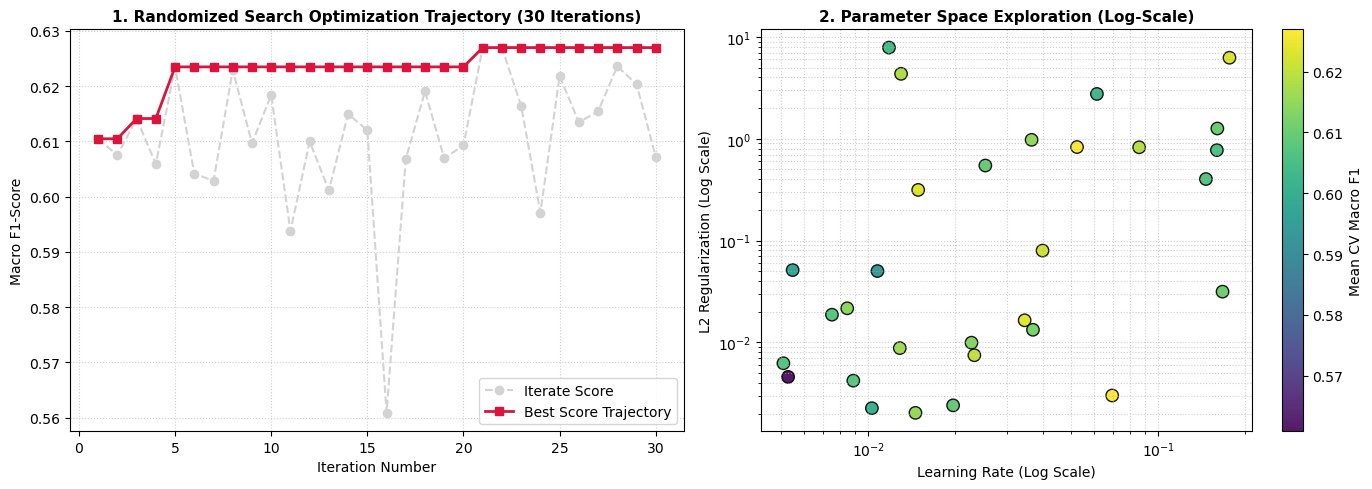

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mean_scores = cv_results_rs['mean_test_score'].values
cum_best_scores = np.maximum.accumulate(mean_scores)

axes[0].plot(range(1, len(mean_scores) + 1), mean_scores, 'o--', color='lightgray', label='Iterate Score')
axes[0].plot(range(1, len(cum_best_scores) + 1), cum_best_scores, 's-', color='crimson', lw=2, label='Best Score Trajectory')
axes[0].set_title("1. Randomized Search Optimization Trajectory (30 Iterations)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Iteration Number")
axes[0].set_ylabel("Macro F1-Score")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right')

learning_rates = cv_results_rs['param_classifier__learning_rate'].astype(float)
l2_regs = cv_results_rs['param_classifier__l2_regularization'].astype(float)
scores = cv_results_rs['mean_test_score'].values

scatter = axes[1].scatter(learning_rates, l2_regs, c=scores, cmap='viridis', s=80, edgecolors='black', alpha=0.9)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title("2. Parameter Space Exploration (Log-Scale)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Learning Rate (Log Scale)")
axes[1].set_ylabel("L2 Regularization (Log Scale)")
axes[1].grid(True, linestyle=':', alpha=0.6, which='both')

cbar = fig.colorbar(scatter, ax=axes[1])
cbar.set_label("Mean CV Macro F1")

plt.tight_layout()
plt.show()